# Влияние числа исходных участков на замыкание пор в UO₂
Исполняемый расчётный пример · Python 3.10+ · Jupyter с NumPy, pandas, Matplotlib и IPython.

Измените значения в блоке 1 и выполните **Restart Kernel and Run All Cells**. Результаты появятся под ячейками и в новой папке запуска. Команды установки для чистого окружения: `python -m pip install jupyterlab numpy pandas matplotlib`, затем `jupyter lab`.

Модель отслеживает переход локальной полости из открытого состояния в замкнутое при закрытии последнего окна. На старте все окна сообщаются с внешней поровой сетью. Группы независимы, повторное открытие исключено. Температура задана одинаковой во всём объёме. Пространственная теплопроводность, последующая усадка и перенос газа в расчёт не входят. Число участков задаёт объём выборки. Для прогноза по реальной прессовке нужны измерения плотности участков и калибровка кинетики.

Каждое значение N задаёт размер вложенной выборки в той же таблетке. При переходе от 50 к 100 первые 50 участков сохраняют координаты, тип и историю окон. Это позволяет выделить вклад добавленных участков. Сценарии статистически связаны.

**Как пользоваться.** Исполните ячейки по порядку в Colab/Jupyter. Примеры со случайной выборкой проверяют поведение уравнений. Параметры рассеяния, число участков и нормировочная длина — настройки численного опыта. Для интерпретации в физических единицах задайте размеры своего образца и измеренные входы. Маркеры на обзорной 3D-картинке показывают центры.

Эффективные параметры закрытия окон и разброс размеров в примере требуют независимой калибровки.

При полном запуске SEED = None выбирает новый seed. Его значение выводится и сохраняется в parameters.json под именем effective_seed. Чтобы повторить реализацию, введите это целое число в SEED и выполните все ячейки. Сохранённые в архиве примеры и изображения получены при SEED = 42.

## Источник исходных данных

**Базовый эксперимент.** Y. W. Rhee и соавт., *In-Situ Observation of Sintering Shrinkage of UO₂ Compacts Derived from Different Powder Routes*, KNS, 2015, § 2–3, рис. 3. Это та же работа, что использована в расчёте полостей. В ней определяли усадку прессовок разных порошковых маршрутов. Исходные габариты прессовки служат координатной рамкой демонстрации. [Исходная публикация](https://www.kns.org/files/pre_paper/34/15A-419%EC%9D%B4%EC%98%81%EC%9A%B0.pdf).

## 1. Условия и параметры пользователя

Все изменяемые входные данные собраны здесь. Тепловое воздействие задаётся длительностью и температурой каждой ступени. Параметры кинетики в примере демонстрационные. Форма цилиндра и открытая начальная сеть задают границы применимости модели.

In [1]:
# Геометрия цилиндра и исходного порошка
R_MM = 5.15
H_MM = 8.5
PARTICLE_UM = 2.5  # Средний эффективный диаметр частиц, мкм
PARTICLE_CV = 0.20  # Стандартное отклонение / среднее; 0 даёт одинаковые частицы

# История температуры: пары (длительность ступени, с; температура, К).
# Для нескольких выдержек добавьте пары в порядке их следования.
THERMAL_STEPS = [(14400, 1973.15)]
BARRIER_EV = 1.0       # Эффективная энергия закрытия одного окна, эВ
ATTEMPT_HZ = 0.1       # Эффективный частотный множитель, 1/с

# Исходная структура. Доля 2/3 соответствует весам тетра:окта = 2:1.
TETRA_FRACTION = 2/3
SITE_COUNTS = [25, 50, 100, 200]  # Размеры сравниваемых выборок, шт.
# Настройки расчёта, воспроизводимости и экспорта
SEED = None
MC_RAYS = 100_000      # Число направлений для оценки объёма каждого типа
SERIES_RUNS = 1000     # Число реализаций на каждый режим
OUTPUT_ROOT = "uo2_site_sweep"

## 2. Проверка ввода и подготовка расчёта

Проверки выполняются до построения модели. Для выбора числа участков, событий, координат и серии используются отдельные потоки случайных чисел. Каждый запуск получает собственную папку.

In [2]:
import itertools, json, math, random
from datetime import datetime, timezone
from pathlib import Path
from statistics import mean, stdev
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

for name in ('MC_RAYS', 'SERIES_RUNS'):
    value = globals()[name]
    minimum = {'MC_RAYS': 2, 'SERIES_RUNS': 2}.get(name, 0)
    if type(value) is not int or value < minimum:
        raise ValueError(f'{name}: требуется целое число от {minimum}')
for value in (R_MM,H_MM,PARTICLE_UM,ATTEMPT_HZ):
    if not math.isfinite(value) or value <= 0:
        raise ValueError('Размеры и частотный множитель должны быть положительными')
if not 0 <= TETRA_FRACTION <= 1:
    raise ValueError('Проверьте долю тетраэдрических участков и режим выборки')
if not all(math.isfinite(x) and x >= 0 for x in (BARRIER_EV,)):
    raise ValueError('Среднее число участков и энергия должны быть конечными и ≥ 0')
if not math.isfinite(PARTICLE_CV) or PARTICLE_CV < 0:
    raise ValueError('PARTICLE_CV должен быть конечным и неотрицательным')
if not THERMAL_STEPS or any(not(math.isfinite(t) and t >= 0 and math.isfinite(T) and T > 0)
                            for t,T in THERMAL_STEPS):
    raise ValueError('Для каждой ступени задайте длительность ≥ 0 с и температуру > 0 К')
if not SITE_COUNTS or any(type(n) is not int or n < 0 for n in SITE_COUNTS) or len(set(SITE_COUNTS)) != len(SITE_COUNTS):
    raise ValueError('SITE_COUNTS: задайте различные неотрицательные целые числа')
if SEED is not None and (type(SEED) is not int or SEED < 0):
    raise ValueError('SEED: None или целое неотрицательное число')
seed = int(np.random.SeedSequence().entropy) if SEED is None else SEED
print('Seed запуска:', seed)
out = Path(OUTPUT_ROOT) / datetime.now().strftime('run_%Y%m%d_%H%M%S_%f')
out.mkdir(parents=True)
settings = {k:globals()[k] for k in ('R_MM','H_MM','PARTICLE_UM','PARTICLE_CV','THERMAL_STEPS',
    'BARRIER_EV','ATTEMPT_HZ','TETRA_FRACTION','SITE_COUNTS',
    'SEED','MC_RAYS','SERIES_RUNS')}
settings['effective_seed'] = seed
(out/'parameters.json').write_text(json.dumps(settings, indent=2),encoding='utf8')
streams = np.random.SeedSequence(seed).spawn(5)
# Один относительный размер для каждого участка, общий для всех вложенных выборок.
size_rng = np.random.default_rng(streams[4])
sigma = np.sqrt(np.log1p(PARTICLE_CV**2))
scales = size_rng.lognormal(-sigma**2/2, sigma, max(SITE_COUNTS))
def show_figure(fig, name, out, preview):
    path = out / (name+'.png')
    fig.savefig(path,dpi=160,bbox_inches='tight',facecolor='white')
    plt.close(fig)
    if preview: display(Image(filename=str(path)))

## 3. Геометрический объём полости

Сохраняем метод Монте-Карло исходного скрипта. Луч из центра полости упирается в ближайшую поверхность частицы. Усреднение куба длины луча по направлениям даёт объём. Расчёт выполняется один раз для каждой идеальной геометрии. Для STEP используем сферу того же объёма. Стандартная ошибка характеризует точность интегрирования.

В каждой группе все частицы имеют общий эффективный диаметр. Между группами диаметр распределён логнормально. При геометрическом подобии диаметр полости масштабируется линейно, а объём и его ошибка Монте-Карло — по кубу масштаба. Разброс 20 % демонстрационный. Скорость закрытия окон в этой модели одинакова для всех размеров.

In [3]:
def closure_volume(kind, particle_um, samples, rng):
    """Solid-angle MC: V = (4*pi/3) E[t_exit(direction)^3].
    Coordinates in units of nearest-neighbour spacing. All triangular throats
    just close at effective particle radius 1/sqrt(3). Each ray intersects a
    particle on/before exiting the polyhedron of centres. First hit bounds pore.
    """
    if kind == "tetra":
        a = 1 / math.sqrt(8)
        centers = [(i*a,j*a,k*a) for i,j,k in itertools.product((-1,1),repeat=3)
                   if i*j*k == 1]
    else:
        a = 1 / math.sqrt(2)
        centers = [(i*a,j*a,k*a) for i,j,k in itertools.product((-1,0,1),repeat=3)
                   if abs(i)+abs(j)+abs(k) == 1]
    gap = sum(x*x for x in centers[0]) - 1/3
    spacing = math.sqrt(3)*particle_um/2
    estimates = []
    for _ in range(samples):
        z = rng.uniform(-1,1)
        angle = rng.random()*math.tau
        rho = math.sqrt(1-z*z)
        x,y = rho*math.cos(angle),rho*math.sin(angle)
        # All particle centres are equidistant from the void centre. The
        # largest projection gives the first sphere hit along this direction.
        b = max(x*i+y*j+z*k for i,j,k in centers)
        disc = b*b-gap
        if disc < -1e-13:
            raise ArithmeticError("ray left the pocket without encountering solid")
        hit = gap / (b+math.sqrt(max(0,disc)))
        estimates.append(4*math.pi/3*(spacing*hit)**3)
    return mean(estimates), stdev(estimates)/math.sqrt(samples)



geometry_rng = random.Random(seed)
geometry = {kind: closure_volume(kind, PARTICLE_UM, MC_RAYS, geometry_rng)
            for kind in ('tetra','octa')}
diam = {kind:(6*v/math.pi)**(1/3) for kind,(v,se) in geometry.items()}

## 4. Кинетика окон и время изоляции

Для окна на ступени с постоянной температурой скорость равна $k=ν\exp[-Q/(k_BT)]$. За время $t$ накапливается интенсивность $A(t)=\int_0^t k(s)ds$. Закрытие наступает, когда она достигает случайного порога с показательным распределением единичного среднего. Время закрытия последнего окна определяет момент изоляции участка. Такой подход сохраняет одну историю для всех точек графика.

In [4]:
KB_EV = 8.617333262145e-5
durations, temperatures = np.asarray(THERMAL_STEPS,dtype=float).T
rates = ATTEMPT_HZ*np.exp(-BARRIER_EV/(KB_EV*temperatures))
ends = np.cumsum(durations)
starts = np.r_[0.,ends[:-1]]
exposure = np.r_[0.,np.cumsum(rates*durations)]
duration = ends[-1]
def q_at(times):
    elapsed = np.clip(np.asarray(times)[...,None]-starts,0,durations)
    return -np.expm1(-np.sum(elapsed*rates,axis=-1))
def closing_times(n, event_rng):
    thresholds = event_rng.exponential(size=n)
    times = np.full(n,np.inf)
    for i,k in enumerate(rates):
        if k > 0:
            hit = (thresholds > exposure[i]) & (thresholds <= exposure[i+1])
            times[hit] = starts[i]+(thresholds[hit]-exposure[i])/k
    return times
q = float(q_at(duration))
p = TETRA_FRACTION*q**4 + (1-TETRA_FRACTION)*q**8

## 5. Размещение групп и журнал всех участков

Центры равномерно выбираются внутри цилиндра с отступом для группы частиц. Проверка расстояний исключает наложение групп. Фиксируем координаты, тип, состояние каждого окна и момент изоляции. Пустое время в CSV означает, что событие не наблюдалось до конца заданной истории температуры.

In [5]:
def simulate(n, out):
    event_rng = np.random.default_rng(streams[1])
    pos_rng = np.random.default_rng(streams[2])
    centers, rows, events, pores = [], [], [], []
    for patch in range(1,n+1):
        scale = scales[patch-1]
        particle_um = PARTICLE_UM*scale
        margin = 2*particle_um*math.sqrt(1.5)/1000
        if not 0 < margin < min(R_MM,H_MM/2):
            raise ValueError(f'Участок {patch}: группа не помещается в цилиндр')
        for attempt in range(10000):
            r = (R_MM-margin)*math.sqrt(pos_rng.random())
            a = pos_rng.uniform(0,2*math.pi)
            xyz = (r*math.cos(a),r*math.sin(a),pos_rng.uniform(margin,H_MM-margin))
            if all(math.dist(xyz,c)>margin+other_margin for c,other_margin in centers):
                break
        else:
            raise ValueError('Недостаточно места для разнесённых групп. Проверьте число и размеры.')
        centers.append((xyz,margin))
        kind = 'tetra' if event_rng.random()<TETRA_FRACTION else 'octa'
        nw = 4 if kind=='tetra' else 8
        times = closing_times(nw, event_rng)
        for j,t in enumerate(times,1):
            events.append((patch,j,t if np.isfinite(t) else np.nan))
        closed = bool(np.isfinite(times.max()))
        vol,se = (value*scale**3 for value in geometry[kind])
        diameter = diam[kind]*scale
        rows.append((patch,kind,*xyz,particle_um,nw,int(np.isinf(times).sum()),closed,
                     times.max() if closed else np.nan,diameter if closed else np.nan,
                     vol if closed else np.nan,se if closed else np.nan))
        if closed:
            pores.append((patch,kind,xyz,diameter/2000,vol,se))
    cols = 'patch kind x_mm y_mm z_mm particle_um windows_initial windows_open closed isolation_s diameter_um volume_um3 volume_mc_se_um3'.split()
    sites = pd.DataFrame(rows,columns=cols)
    sites['closed'] = sites.closed.astype(bool)
    closed_sites = sites.loc[sites.closed].copy()
    sites.to_csv(out/'all_sites.csv',index=False)
    closed_sites.to_csv(out/'closed_pores.csv',index=False)
    pd.DataFrame(events,columns=['patch','window','closure_s']).to_csv(out/'windows.csv',index=False)
    return sites, closed_sites, pores, events

## 6. Сводка реализации

Сравниваем число закрытых полостей с исходным числом участков отдельно по типам. Знаменатель важен для сравнения вероятностей. Объём дан для рассчитанных закрытых полостей выборки.

In [6]:
names = {'tetra':'Тетраэдрические','octa':'Октаэдрические'}
def summarize(sites, closed_sites, n, pores, out, preview):
    summary = []
    for kind,label in names.items():
        group = sites[sites.kind==kind]
        done = group[group.closed]
        summary.append([label,len(group),len(group)-len(done),len(done),
                        len(done)/len(group) if len(group) else np.nan,
                        q**(4 if kind=='tetra' else 8),done.diameter_um.mean(),done.volume_um3.sum()])
    summary.append(['Вся выборка',n,n-len(pores),len(pores),len(pores)/n if n else np.nan,
                    p,closed_sites.diameter_um.mean(),closed_sites.volume_um3.sum()])
    table = pd.DataFrame(summary,columns=['Тип','Исходные','Открытые','Замкнутые',
        'Доля замкнутых','Вероятность по модели','Средний диаметр замкнутых пор, мкм','Объём замкнутых, мкм³'])
    table.to_csv(out/'summary.csv',index=False)
    if preview: display(table.round(5))
    return table

## 7. Кинетика замыкания

Сплошные ступенчатые линии показывают события одного запуска. Пунктир показывает теоретическую вероятность $q(t)^m$, где $m$ равно 4 или 8. Доля рассчитывается внутри типа. Если участков одного типа нет, для него выводится только теория.

In [7]:
colors = {'tetra':'#00798a','octa':'#ae4725'}
def plot_kinetics(sites, out, preview):
    grid = np.unique(np.r_[np.linspace(0,duration,401), ends])
    fig,ax = plt.subplots(figsize=(8,4))
    kinetics = []
    for kind,label in names.items():
        group = sites[sites.kind==kind]
        times = np.sort(group.isolation_s.dropna().to_numpy(dtype=float))
        theory = q_at(grid)**(4 if kind=='tetra' else 8)
        if len(group):
            ax.step(np.r_[0,times,duration]/3600,100*np.r_[0,np.arange(1,len(times)+1),len(times)]/len(group),
                    where='post',color=colors[kind],label=label)
        ax.plot(grid/3600,100*theory,'--',color=colors[kind],label=label+' · теория')
        observed = np.searchsorted(times,grid,side='right')/len(group) if len(group) else np.full(len(grid),np.nan)
        kinetics.extend(zip([kind]*len(grid),grid,observed,theory))
    ax.set(xlabel='Время, ч',ylabel='Замкнутые участки своего типа, %',ylim=(-2,103))
    ax.grid(alpha=.2); ax.legend(fontsize=8)
    show_figure(fig,'kinetics',out,preview)
    pd.DataFrame(kinetics,columns=['kind','time_s','observed_fraction','theory_probability']).to_csv(out/'kinetics.csv',index=False)


## 8. Число пор и вклад в объём

Две полосы сравнивают долю каждого типа в числе и объёме замкнутых пор. Нормирование каждой полосы на 100 % позволяет увидеть вклад крупных пор.

In [8]:
def plot_contributions(closed_sites, pores, out, preview):
    fig,ax = plt.subplots(figsize=(8,2.6))
    if len(pores):
        totals = np.array([len(pores),closed_sites.volume_um3.sum()])
        left = np.zeros(2)
        for kind,label in names.items():
            g = closed_sites[closed_sites.kind==kind]
            share = 100*np.array([len(g),g.volume_um3.sum()])/totals
            ax.barh([1,0],share,left=left,color=colors[kind],label=label,height=.55)
            for y,w,start in zip([1,0],share,left):
                if w>=4: ax.text(start+w/2,y,f'{w:.1f}%',ha='center',va='center',color='white',fontsize=8)
            left += share
        ax.legend(loc='upper center',bbox_to_anchor=(.5,-.28),ncol=2)
    else:
        ax.text(.5,.5,'Замкнутых пор нет',transform=ax.transAxes,ha='center')
    ax.set(yticks=[1,0],yticklabels=['Число','Объём'],xlim=(0,100),xlabel='Доля, %')
    show_figure(fig,'contributions',out,preview)


## 9. Геометрия и распределение диаметров

Слева видны центры замкнутых пор, справа — распределения их фактических расчётных диаметров по типам. У всех вариантов одинаковые интервалы гистограммы.


In [9]:
def plot_geometry(closed_sites, out, preview):
    fig = plt.figure(figsize=(9,4.2))
    ax = fig.add_subplot(121,projection='3d')
    angle = np.linspace(0,2*np.pi,181)
    for z in (0,H_MM):
        ax.plot(R_MM*np.cos(angle),R_MM*np.sin(angle),np.full_like(angle,z),color='#82949c',lw=1)
    for a in np.arange(4)*np.pi/2:
        ax.plot([R_MM*np.cos(a)]*2,[R_MM*np.sin(a)]*2,[0,H_MM],color='#bcc6cb',lw=.6)
    for kind,label in names.items():
        g = closed_sites[closed_sites.kind==kind]
        ax.scatter(g.x_mm,g.y_mm,g.z_mm,s=9,color=colors[kind],label=label)
    ax.set_box_aspect((2*R_MM,2*R_MM,H_MM))
    ax.set(xlabel='x, мм',ylabel='y, мм',zlabel='z, мм',title='Центры замкнутых пор')
    ax.set(xlim=(-R_MM,R_MM),ylim=(-R_MM,R_MM),zlim=(0,H_MM))
    ax.view_init(elev=25,azim=-60)
    ax.legend(fontsize=7)
    ax = fig.add_subplot(122)
    # Общие интервалы для обоих типов и всех N; высота столбца — число пор.
    upper = max(diam.values()) * (max(scales) if len(scales) else 1)
    bins = np.linspace(0,upper*1.02,31)
    for kind,label in names.items():
        group = closed_sites.loc[closed_sites.kind==kind,'diameter_um']
        if len(group):
            ax.hist(group,bins=bins,histtype='step',lw=2,color=colors[kind],label=label)
    if len(closed_sites):
        ax.legend(fontsize=7)
    else:
        ax.text(.5,.5,'Замкнутых пор нет',transform=ax.transAxes,ha='center')
    ax.set(xlim=(0,bins[-1]),xlabel='Эквивалентный диаметр, мкм',ylabel='Число пор')
    ax.set_title('Распределение по размерам')
    fig.tight_layout()
    show_figure(fig,'geometry',out,preview)


## 10. Серия реализаций

Для сравнения двух режимов считаем конечные события напрямую по вероятности из блока 4. Это тот же закон замыкания при независимых группах. Для гистограмм координаты и промежуточные моменты не нужны. Нулевые выборки учитываются в числе пор; их доля замыкания не определена. Для каждого N среднее пуассоновской выборки равно N.

In [10]:
def ensemble(n, out, preview):
    series_rng = np.random.default_rng(np.random.SeedSequence([seed, n, 3]))
    fig,axes = plt.subplots(1,2,figsize=(10,3.5))
    runs = []
    for mode in ('fixed','poisson'):
        ns = np.full(SERIES_RUNS,n) if mode=='fixed' else series_rng.poisson(n,SERIES_RUNS)
        nt = series_rng.binomial(ns,TETRA_FRACTION)
        nc = series_rng.binomial(nt,q**4)+series_rng.binomial(ns-nt,q**8)
        frac = np.divide(nc,ns,out=np.full(SERIES_RUNS,np.nan),where=ns>0)
        runs.append(pd.DataFrame(dict(mode=mode,run=np.arange(1,SERIES_RUNS+1),initial=ns,closed=nc,fraction=frac)))
    runs = pd.concat(runs,ignore_index=True)
    for ax,key,label in zip(axes,['closed','fraction'],['Замкнутые поры, шт.','Доля замкнувшихся участков']):
        full = runs[key].dropna()
        bins = np.histogram_bin_edges(full,bins=25) if len(full) else np.linspace(0,1,11)
        for mode,title,color in [('fixed','Фиксированное число','#00798a'),('poisson','Случайное число','#ae4725')]:
            g = runs.loc[runs['mode']==mode,key].dropna()
            if len(g):
                ax.hist(g,bins=bins,weights=np.ones(len(g))/len(g),histtype='step',lw=2,color=color,label=title)
        ax.set(xlabel=label,ylabel='Доля реализаций')
        if ax.get_legend_handles_labels()[0]: ax.legend(fontsize=8)
    fig.tight_layout()
    show_figure(fig,'ensemble',out,preview)
    runs.to_csv(out/'ensemble.csv',index=False)
    stats = runs.groupby('mode').agg(mean_closed=('closed','mean'),sd_closed=('closed','std'),
                                     mean_fraction=('fraction','mean'))
    stats['theory_mean_closed'] = [n*p,n*p]
    stats['theory_sd_closed'] = [math.sqrt(n*p*(1-p)),math.sqrt(n*p)]
    if preview: display(stats.round(4))
    stats.to_csv(out/'ensemble_summary.csv')
    return stats


## 11. Экспорт твердотельной модели STEP

Функция из исходного проекта строит наружную цилиндрическую оболочку и внутренние сферические оболочки. Координаты и радиусы записываются в миллиметрах. Пустая выборка даёт сплошной цилиндр.

In [11]:
def write_step(path, pores):
    entities=[]
    def add(expr):
        entities.append(expr)
        return "#"+str(len(entities))
    def v(type_,*args):
        return add(type_+"('',"+",".join(args)+")")
    def seq(args):
        return "("+",".join(args)+")"
    def point(x,y,z):
        return v("CARTESIAN_POINT",seq([str(float(q)) for q in (x,y,z)]))
    def direction(x,y,z):
        return v("DIRECTION",seq([str(float(q)) for q in (x,y,z)]))
    def edge(a,b,g):
        return v("EDGE_CURVE",a,b,g,".T.")
    def face(edges,surf,orientation):
        oriented=[v("ORIENTED_EDGE","*","*",e,".T." if sign else ".F.") for e,sign in edges]
        loop=v("EDGE_LOOP",seq(oriented))
        bound=v("FACE_OUTER_BOUND",loop,".T.")
        return v("ADVANCED_FACE",seq([bound]),surf,orientation)
    x=direction(1,0,0)
    z=direction(0,0,1)
    up=v("VECTOR",z,"1.")
    r,h=R_MM,H_MM
    arcs=[]; planes=[]; vertices=[]; axes=[]; points=[]
    for level in (0,h):
        ax=v("AXIS2_PLACEMENT_3D",point(0,0,level),z,x)
        axes.append(ax)
        circle=v("CIRCLE",ax,str(r))
        pp=[point(r,0,level),point(-r,0,level)]
        points.append(pp)
        a,b=[v("VERTEX_POINT",p) for p in pp]
        vertices.append((a,b))
        arcs.append((edge(a,b,circle),edge(b,a,circle)))
        planes.append(v("PLANE",ax))
    sides=[edge(vertices[0][i],vertices[1][i],v("LINE",points[0][i],up)) for i in range(2)]
    cyl=v("CYLINDRICAL_SURFACE",axes[0],str(r))
    faces=[face([(arcs[0][1],False),(arcs[0][0],False)],planes[0],".F."),
           face([(a,True) for a in arcs[1]],planes[1],".T.")]
    for i in range(2):
        j=1-i
        faces.append(face([(arcs[0][i],True),(sides[j],True),(arcs[1][i],False),(sides[i],False)],cyl,".T."))
    outer = v("CLOSED_SHELL",seq(faces))
    voids = []
    unit = [(1,0,0),(-1,0,0),(0,1,0),(0,-1,0),(0,0,1),(0,0,-1)]
    def cross(a,b):
        return (a[1]*b[2]-a[2]*b[1],a[2]*b[0]-a[0]*b[2],a[0]*b[1]-a[1]*b[0])
    for _,_,center,radius,_,_ in pores:
        cp = point(*center)
        loc = v("AXIS2_PLACEMENT_3D",cp,z,x)
        sphere = v("SPHERICAL_SURFACE",loc,f"{radius:.14f}")
        vertices = [v("VERTEX_POINT",point(*(c+radius*d for c,d in zip(center,q)))) for q in unit]
        edges = {}
        faces = []
        for i,j,k in itertools.product((0,1),(2,3),(4,5)):
            ids = [i,j,k]
            if sum(a*b for a,b in zip(cross(unit[i],unit[j]),unit[k]))<0:
                ids.reverse()
            loop = []
            for a,b in zip(ids,ids[1:]+ids[:1]):
                low,high=sorted((a,b))
                if (low,high) not in edges:
                    ax=v("AXIS2_PLACEMENT_3D",cp,direction(*cross(unit[low],unit[high])),direction(*unit[low]))
                    circle=v("CIRCLE",ax,f"{radius:.14f}")
                    edges[low,high]=edge(vertices[low],vertices[high],circle)
                loop.append((edges[low,high],a==low))
            faces.append(face(loop,sphere,".T."))
        shell=v("CLOSED_SHELL",seq(faces))
        voids.append(v("ORIENTED_CLOSED_SHELL","*",shell,".F."))
    body = (v("BREP_WITH_VOIDS", outer, seq(voids)) if voids
            else v("MANIFOLD_SOLID_BREP", outer))
    app=add("APPLICATION_CONTEXT('automotive_design')")
    add("APPLICATION_PROTOCOL_DEFINITION('international standard','automotive_design',2000,"+app+")")
    pc=add("PRODUCT_CONTEXT('',"+app+",'mechanical')")
    prod=add("PRODUCT('Rhee','UO2 green compact','',("+pc+"))")
    formation=add("PRODUCT_DEFINITION_FORMATION('','',"+prod+")")
    dc=add("PRODUCT_DEFINITION_CONTEXT('part definition',"+app+",'design')")
    pd=add("PRODUCT_DEFINITION('design','',"+formation+","+dc+")")
    shape=add("PRODUCT_DEFINITION_SHAPE('','',"+pd+")")
    units=[add("( LENGTH_UNIT() NAMED_UNIT(*) SI_UNIT(.MILLI.,.METRE.) )"),add("( NAMED_UNIT(*) PLANE_ANGLE_UNIT() SI_UNIT($,.RADIAN.) )"),add("( NAMED_UNIT(*) SI_UNIT($,.STERADIAN.) SOLID_ANGLE_UNIT() )")]
    tol=add("UNCERTAINTY_MEASURE_WITH_UNIT(LENGTH_MEASURE(1.E-9),"+units[0]+",'distance_accuracy_value','')")
    ctx=add("( GEOMETRIC_REPRESENTATION_CONTEXT(3) GLOBAL_UNCERTAINTY_ASSIGNED_CONTEXT(("+tol+")) GLOBAL_UNIT_ASSIGNED_CONTEXT("+seq(units)+") REPRESENTATION_CONTEXT('','') )")
    rep=v("ADVANCED_BREP_SHAPE_REPRESENTATION",seq([body,axes[0]]),ctx)
    add("SHAPE_DEFINITION_REPRESENTATION("+shape+","+rep+")")
    stamp=datetime.now(timezone.utc).isoformat(timespec="seconds")
    with path.open("w",encoding="ascii") as f:
        f.write("ISO-10303-21;\nHEADER;\nFILE_DESCRIPTION(('Microscopic closure pockets'),'2;1');\n")
        f.write(f"FILE_NAME('rhee_micro.step','{stamp}',(''),(''),'','pellet_step','');\n")
        f.write("FILE_SCHEMA(('AUTOMOTIVE_DESIGN'));\nENDSEC;\nDATA;\n")
        for n,entity in enumerate(entities,1):
            f.write(f"#{n}={entity};\n")
        f.write("ENDSEC;\nEND-ISO-10303-21;\n")

## 12. Контроль согласованности и сохранение STEP

Проверяем связь CSV с событиями, попадание сфер внутрь таблетки и согласованность числа внутренних оболочек STEP. Новый каталог содержит исходные настройки, CSV, четыре рисунка и модель. Для повтора используйте те же настройки и seed.

In [12]:
def export_step(n, sites, closed_sites, pores, events, out):
    assert len(sites)==n and len(closed_sites)==len(pores)
    assert (sites.closed == (sites.windows_open==0)).all()
    assert len(events)==sum(sites.windows_initial)
    for _,_,(x,y,z),r,_,_ in pores:
        assert math.hypot(x,y)+r < R_MM and r < z < H_MM-r
    step_path = out/'rhee_micro.step'
    write_step(step_path,pores)
    assert step_path.read_text(encoding='ascii').count('ORIENTED_CLOSED_SHELL(')==len(pores)


## 13. Расчёт для каждого N

Для каждого размера записываются собственные таблицы, рисунки, параметры и STEP. Подробные рисунки выводятся в ноутбуке для наибольшей выборки. Гистограммы в каждой папке сравнивают фиксированное N с пуассоновской выборкой того же среднего размера.

,Тип,Исходные,Открытые,Замкнутые,Доля замкнутых,Вероятность по модели,"Средний диаметр замкнутых пор, мкм","Объём замкнутых, мкм³"
0,Тетраэдрические,129,8,121,0.93798,0.93007,0.24952,1.11196
1,Октаэдрические,71,9,62,0.87324,0.86503,0.79532,17.69683
2,Вся выборка,200,17,183,0.91500,0.90839,0.43443,18.80880


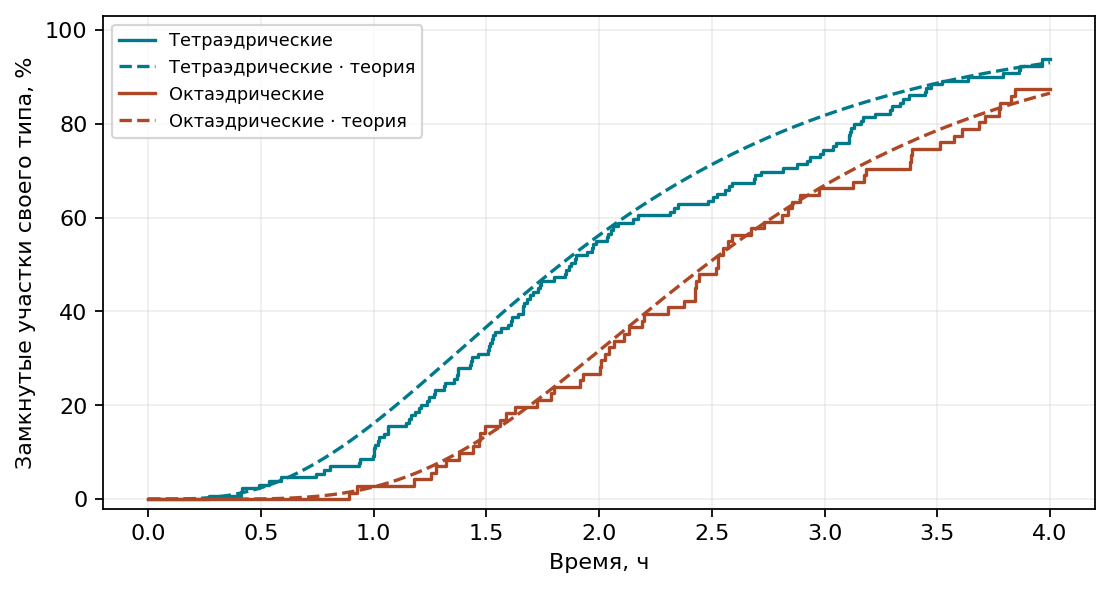

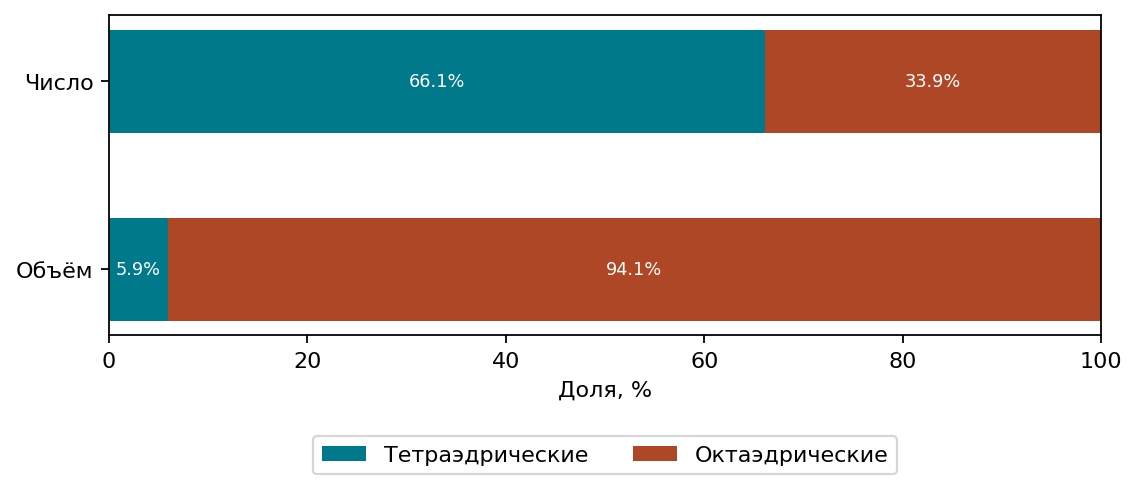

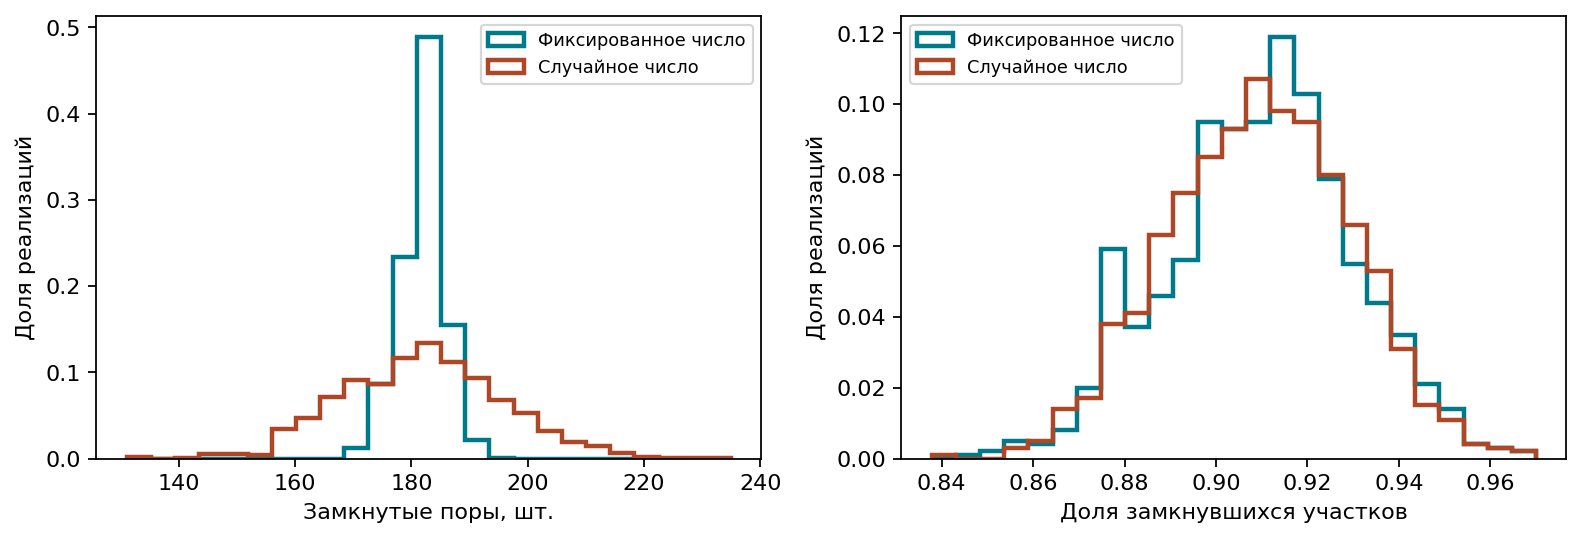

,mean_closed,sd_closed,mean_fraction,theory_mean_closed,theory_sd_closed
mode,,,,,
fixed,181.999,3.9702,0.9100,181.6786,4.0796
poisson,182.046,13.9026,0.9093,181.6786,13.4788


,initial,closed,open,fraction,expected_closed,theory_probability,volume_um3,ensemble_mean,ensemble_sd
0,25,21,4,0.840,22.7098,0.9084,2.7150,22.729,1.4330
1,50,43,7,0.860,45.4196,0.9084,4.0417,45.346,1.9966
2,100,90,10,0.900,90.8393,0.9084,9.6399,90.892,2.9575
3,200,183,17,0.915,181.6786,0.9084,18.8088,181.999,3.9702


In [13]:
records = []
for n in sorted(SITE_COUNTS):
    folder = out / f'N_{n}'
    folder.mkdir(exist_ok=True)
    preview = n == max(SITE_COUNTS)
    (folder/'parameters.json').write_text(json.dumps(dict(settings, initial_sites=n),indent=2),encoding='utf8')
    sites, closed_sites, pores, events = simulate(n,folder)
    table = summarize(sites,closed_sites,n,pores,folder,preview)
    plot_kinetics(sites,folder,preview)
    plot_contributions(closed_sites,pores,folder,preview)
    plot_geometry(closed_sites,folder,False)
    stats = ensemble(n,folder,preview)
    export_step(n,sites,closed_sites,pores,events,folder)
    records.append(dict(initial=n,closed=len(pores),open=n-len(pores),
                        fraction=len(pores)/n if n else np.nan,expected_closed=n*p,
                        theory_probability=p,volume_um3=closed_sites.volume_um3.sum(),
                        ensemble_mean=stats.loc['fixed','mean_closed'],
                        ensemble_sd=stats.loc['fixed','sd_closed']))
comparison = pd.DataFrame(records)
comparison.to_csv(out/'comparison.csv',index=False)
display(comparison.round(4))

## 14. Сравнение размеров выборки

Слева сопоставляются наблюдаемое число замыканий, среднее по повторным реализациям и ожидание Np. Справа показаны наблюдаемые доли. При фиксированной температурной истории вероятность p одинакова для всех N. Доля для нулевой выборки не определена.

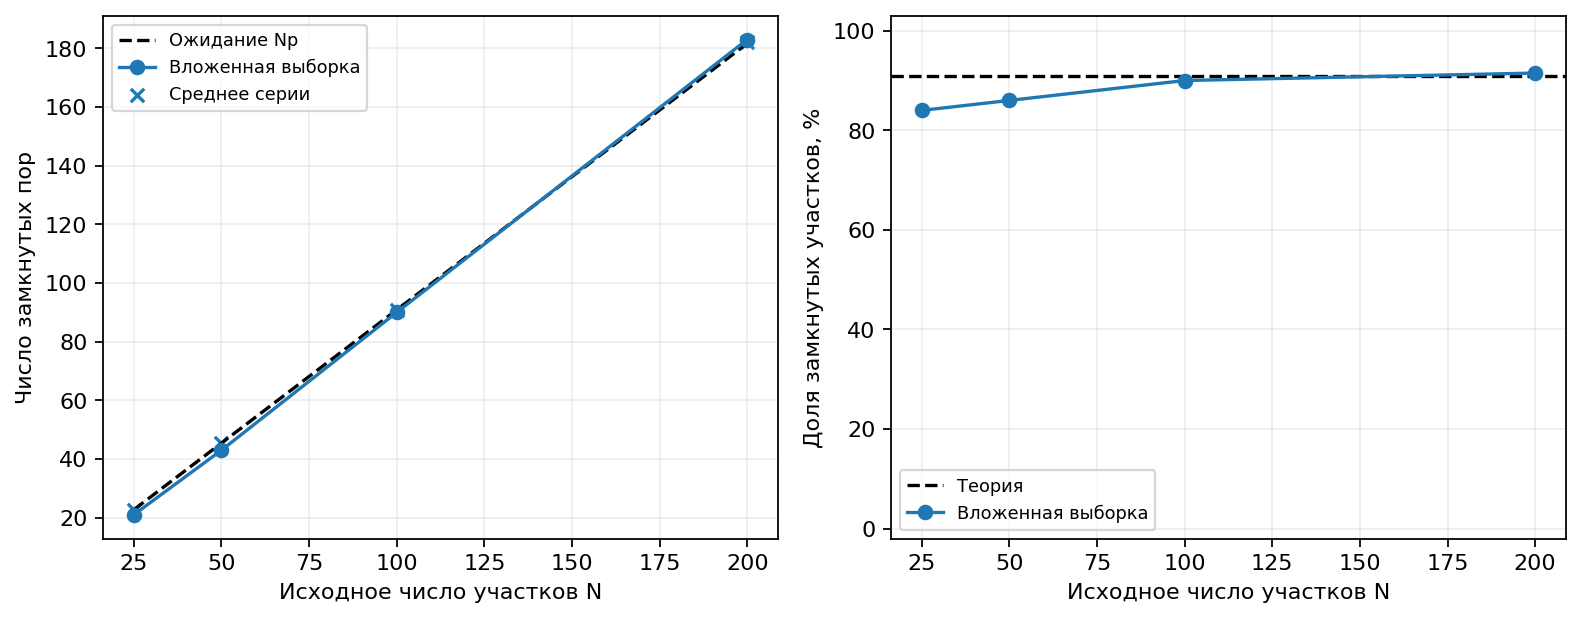

Результаты сохранены в uo2_site_sweep/run_20261122_003154_401727


In [14]:
fig,(a,b) = plt.subplots(1,2,figsize=(10,4))
x = comparison.initial
a.plot(x,comparison.expected_closed,'--',color='black',label='Ожидание Np')
a.plot(x,comparison.closed,'o-',label='Вложенная выборка')
a.scatter(x,comparison.ensemble_mean,marker='x',label='Среднее серии')
b.axhline(100*p,ls='--',color='black',label='Теория')
b.plot(x,100*comparison.fraction,'o-',label='Вложенная выборка')
for ax,ylabel in [(a,'Число замкнутых пор'),(b,'Доля замкнутых участков, %')]:
    ax.set(xlabel='Исходное число участков N',ylabel=ylabel)
    ax.grid(alpha=.2)
    ax.legend(fontsize=8)
b.set_ylim(-2,103)
fig.tight_layout()
show_figure(fig,'comparison',out,True)
print('Результаты сохранены в',out)

## 15. Галерея всех трёхмерных моделей

Маркеры показывают координаты пор из модели STEP, а гистограммы — их индивидуальные диаметры. Ракурс и геометрический масштаб одинаковы для всей серии.

### Исходных участков — 25 · замкнутых пор — 21

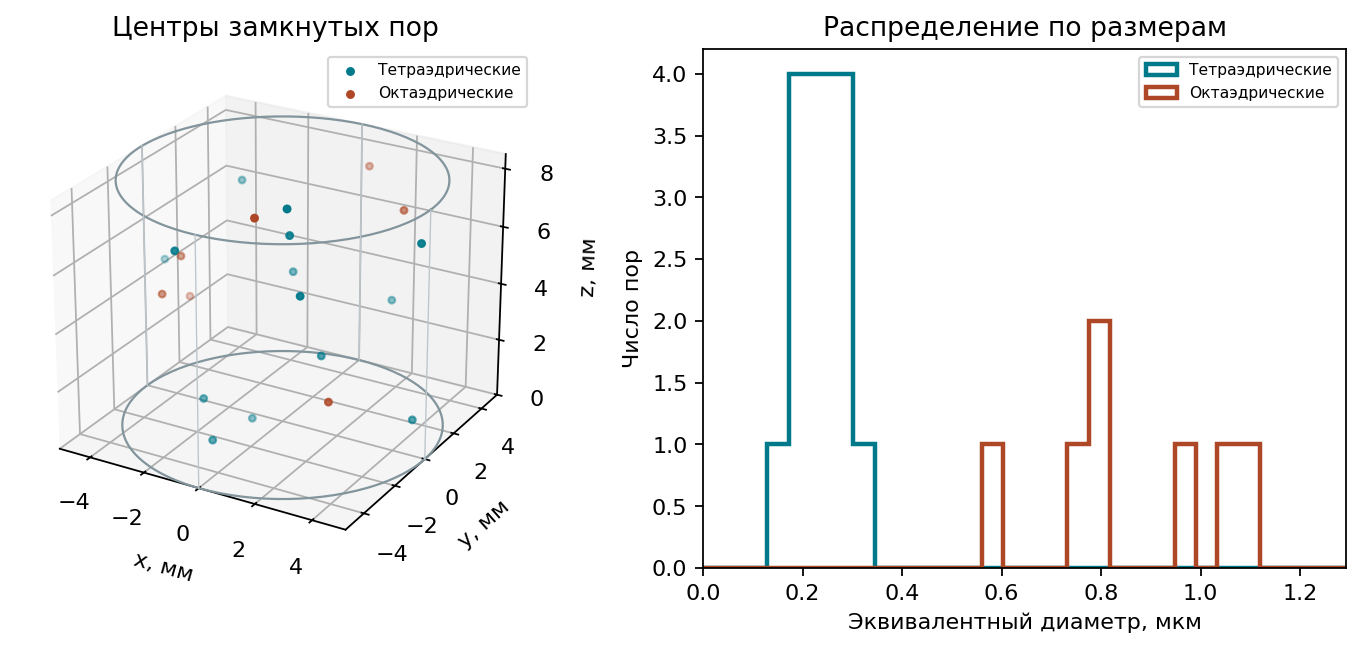

### Исходных участков — 50 · замкнутых пор — 43

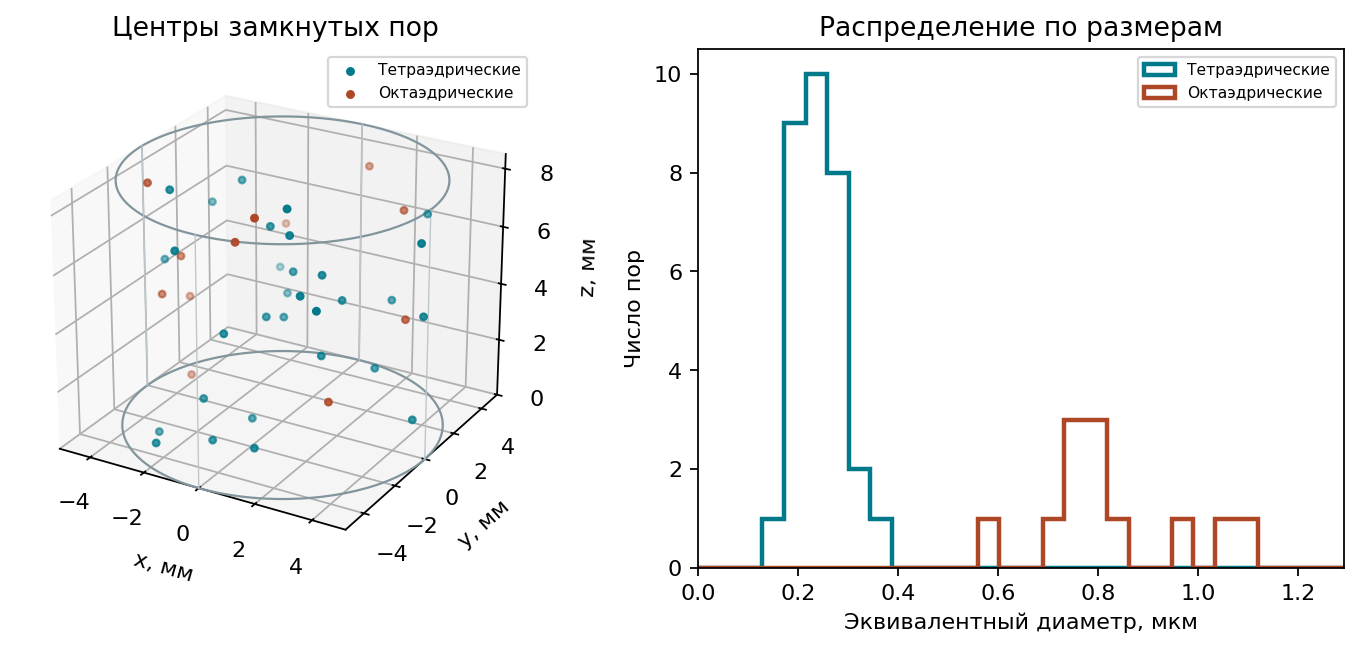

### Исходных участков — 100 · замкнутых пор — 90

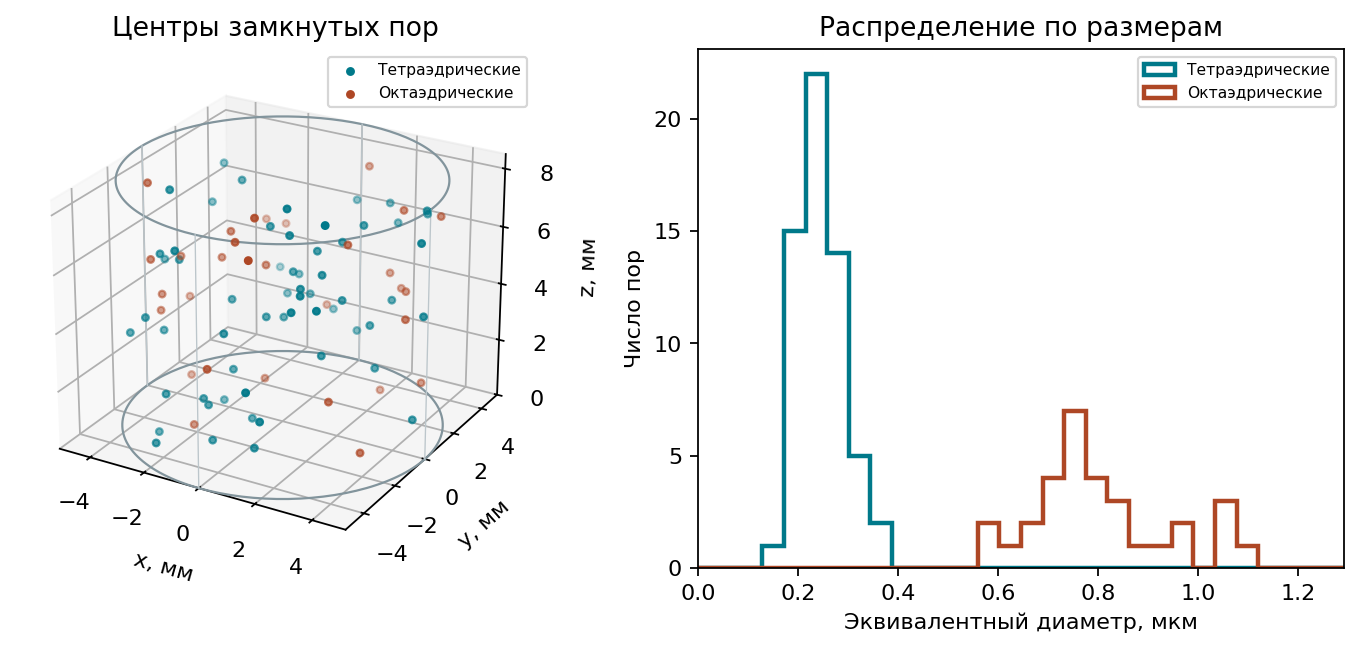

### Исходных участков — 200 · замкнутых пор — 183

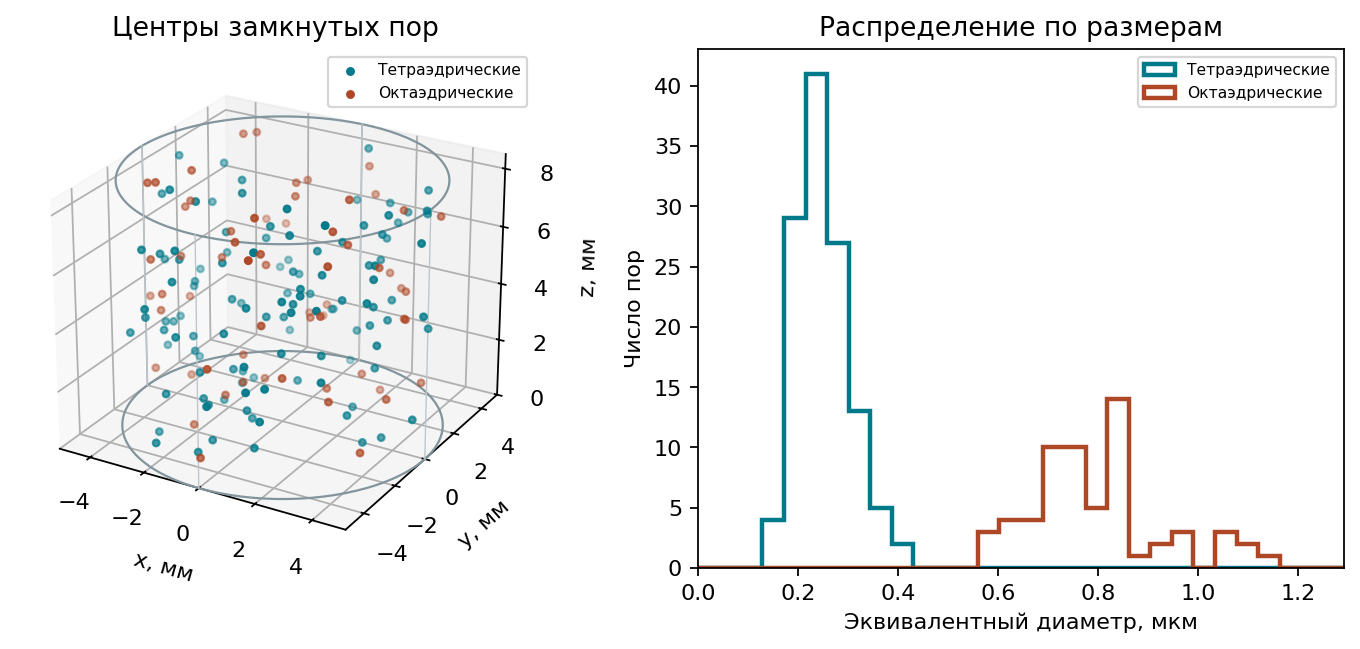

In [15]:
from IPython.display import Markdown

for case in comparison.itertuples(index=False):
    display(Markdown(f'### Исходных участков — {case.initial} · замкнутых пор — {case.closed}'))
    display(Image(filename=str(out / f'N_{case.initial}' / 'geometry.png')))